## customized ENV

In [1]:
import matplotlib.pyplot as plt

In [39]:
import numpy as np

#mohit ra bsurat class tarif mikonim
#func setaup faghat yekbar zaman sakht obj az class call mishe
# func reset ra mitavanim harbar pas az payan episode callkonim ta be state shoro jadid bravim

class GridWorldEnv:
    def __init__(self, num_row, num_col, max_reward=40, max_step=100): #max_reward= reward state payan - max_step = max stepi k agent ta residan b state payan mitavand beravad
        self.num_row = num_row
        self.num_col = num_col
        self.max_reward = max_reward
        self.max_step = max_step

        self.time_step = 0 #shomarande step
        self.obs_shape = (num_row , num_col) # size bordar vijegi har state
        self.action_shape = 4 #bala-paeen-chap-rast
        self._setup()

    def _setup(self): #meghdar dadn b state shoro - state payan - state tale
        row_pos = np.random.randint(0 , self.num_row)
        col_pos = np.random.randint(0 , self.num_col)
        self.agent_pos = np.array([row_pos , col_pos]) #ساختن وضعیت شروع بصورت تصادفی
        while True:
            row_pos = np.random.randint(0 , self.num_row)
            col_pos = np.random.randint(0 , self.num_col)
            self.goal_pos = np.array([row_pos , col_pos]) #ساختن وضعیت هدف(پایان) بامقادیر رندوم
            if not np.array_equal(self.goal_pos , self.agent_pos):
                #باید بررسی کنیم که وضعیت پایان روی وضعیت شروع نیوفتاده باشد
                break
        while True:
            row_pos = np.random.randint(0 , self.num_row)
            col_pos = np.random.randint(0 , self.num_col)
            self.trap_pos = np.array([row_pos , col_pos]) #ساختن وضعیت تله (پاداش منفی دارد) بامقادیر رندوم
            if (not np.array_equal(self.goal_pos , self.trap_pos)) and (not np.array_equal(self.trap_pos, self.agent_pos)):
                #باید بررسی کنیم که وضعیت تله روی وضعیت شروع و هدف نیوفتاده باشد
                break

    def reset(self):
        self.time_step = 0 # ba reset kardn step niz reset mishavad
        while True:
            row_pos = np.random.randint(0 , self.num_row)
            col_pos = np.random.randint(0 , self.num_col)
            self.agent_pos = np.array([row_pos , col_pos]) #ساختن وضعیت شروع جدید بامقادیر رندوم
            if (not np.array_equal(self.goal_pos , self.agent_pos)) and (not np.array_equal(self.trap_pos, self.agent_pos)):
                # باید بررسی کنیم که وضعیت شروع جدید روی وضعیت تله و پایان (ثابت) نیوفتاده باشد
                break
        return self.agent_pos

    def step(self , action):
        self.time_step +=1

        if action == 0 and self.agent_pos[0] < self.num_row - 1: # pain omadan , nadayad az labe ofoghi kharej she
            self.agent_pos[0] += 1
        elif action == 1 and self.agent_pos[1] < self.num_col - 1: # rast raftan , nabayd az labe amudi kharej she
            self.agent_pos[1] += 1
        elif action == 2 and self.agent_pos[0] > 0: #  bala raftan , nabayad az satr 0 balatar bere
            self.agent_pos[0] -= 1
        elif action == 3 and self.agent_pos[1] > 0: # chap raftan , nabayad az sotun 0 chap tar bere
            self.agent_pos[1] -= 1

        # barrc done shodane bazi
        done_win = np.array_equal(self.agent_pos , self.goal_pos) # done shodan barande
        done_lose = np.array_equal(self.agent_pos , self.trap_pos) # done shodane bazande
        done_time = self.time_step > self.max_step # done bar asar etmem step ha
        done = done_win or done_time or done_lose

        #reward
        reward = -1 # baraye har state -1 gharar midahim ta targhib shavad b samte goal
        if done_win:
            reward = self.max_reward
        if done_lose:
            reward = -self.max_reward
        if done_time:
            reward = -self.max_reward
        return self.agent_pos.copy() , reward , done
        #agent_pos = next state

    def render(self):
        fig, ax = plt.subplots(figsize=(6, 6))

        # =========================================
        # محدوده Grid
        # =========================================

        ax.set_xlim(0, self.num_col)
        ax.set_ylim(self.num_row, 0)

        # =========================================
        # خطوط Grid
        # =========================================

        ax.set_xticks(np.arange(self.num_col + 1))
        ax.set_yticks(np.arange(self.num_row + 1))

        ax.grid(
            True,
            linewidth=1.5
        )

        # =========================================
        # برچسب خانه‌ها
        # =========================================

        ax.set_xticklabels([])
        ax.set_yticklabels([])

        # =========================================
        # مختصات مرکز هر خانه
        # =========================================

        # نکته مهم:
        # خانه ستون 0 مرکز x = 0.5 دارد
        # خانه ستون 1 مرکز x = 1.5 دارد
        #
        # خانه سطر 0 مرکز y = 0.5 دارد
        # خانه سطر 1 مرکز y = 1.5 دارد

        # =========================================
        # Goal
        # =========================================

        goal_x = self.goal_pos[1] + 0.5
        goal_y = self.goal_pos[0] + 0.5

        ax.scatter(
            goal_x,
            goal_y,
            s=700,
            marker='*',
            label='Goal',
            zorder=5
        )

        # =========================================
        # Trap
        # =========================================

        trap_x = self.trap_pos[1] + 0.5
        trap_y = self.trap_pos[0] + 0.5

        ax.scatter(
            trap_x,
            trap_y,
            s=450,
            marker='X',
            label='Trap',
            zorder=5
        )

        # =========================================
        # Agent
        # =========================================

        agent_x = self.agent_pos[1] + 0.5
        agent_y = self.agent_pos[0] + 0.5

        ax.scatter(
            agent_x,
            agent_y,
            s=500,
            marker='o',
            edgecolors='black',
            linewidths=2,
            label='Agent',
            zorder=10
        )

        # =========================================
        # شماره Step
        # =========================================

        ax.set_title(
            f"GridWorld\nStep: {self.time_step}",
            fontsize=16
        )

        # =========================================
        # Legend
        # =========================================

        ax.legend(
            loc='upper right',
            fontsize=10
        )

        # =========================================
        # تبدیل Matplotlib Figure به تصویر
        # =========================================

        fig.canvas.draw()

        width, height = fig.canvas.get_width_height()

        frame = np.frombuffer(
            fig.canvas.buffer_rgba(),
            dtype=np.uint8
        )

        frame = frame.reshape(
            height,
            width,
            4
        )

        # RGBA → RGB
        frame = frame[:, :, :3]

        plt.close(fig)

        return frame

## Tabular QLearning

In [40]:
class TabularQlearning:
    def __init__(self, state_shape, num_action, epsilon=0.1, learning_rate=0.001, discount_factor=0.9):
        self.state_shape = state_shape
        self.num_action = num_action
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.epsilon = epsilon

        self.q_table = np.zeros((*state_shape, num_action)) #tarif table Q , satrha tedad state ha , stunha tedad action ha
        self.n_table = np.zeros((*state_shape, num_action)) # zakhire tedad dafaat visist haryek az khoneh ha

    def select_action(self, state):
        q_values = self.q_table[state[0], state[1] , :] #state ha besurat tuple 2 taee yani mahal gharar giri point roye grid ast (x , y)
        # daryaft q_values b ezaye tamam action haye momken dar in state khas
        if np.random.rand() < self.epsilon: #esploration
            action=np.random.randint(0, self.num_action)
        else:#exploitation
            action = np.argmax(q_values)
        return action

    def explore(self, state):
      action = np.argmin(self.n_table[state[0] , state[1], :]) # darim action k kamter entekhab shode ro entekhab mikonim baray explor behtar
      self.n_table[state[0] , state[1], action] +=1 #yek vahed visit on action dar in state khas ro afzayesh dadim
      return action


    def update(self, state, next_state, reward, action):
        cur_q_value = self.q_table[state[0] , state[1] , action] # estekhraj q value feli action entekhabi
        next_q_values = self.q_table[next_state[0], next_state[1], :] # estekhraj q value be ezaye tamam action haye momken dar state badi
        best_next_q_value = max(next_q_values) #target
        new_q_value = cur_q_value + self.learning_rate * (reward + self.discount_factor * best_next_q_value - cur_q_value)
        self.q_table[state[0] , state[1] , action] = new_q_value




$\hat{Q}(s,a) ←  \hat{Q}(s,a) + \alpha (r + \gamma max_a \hat{Q}(s',a') - \hat{Q}(s,a)) $

In [41]:
env = GridWorldEnv(6,6)
n_episodes = 1000
agent = TabularQlearning(env.obs_shape, env.action_shape)

total_reward=[]

for i in range(n_episodes): # explore
    state = env.reset()
    episode_rewards=[]
    while True: # gam haye yek episode
        action=agent.explore(state)
        next_state,reward,done= env.step(action)
        episode_rewards.append(reward)
        agent.update(state, next_state, reward, action)
        state=next_state
        if done:
            break
    total_reward.append(np.sum(episode_rewards))

for i in range(n_episodes):
    state = env.reset()
    episode_rewards=[]
    while True: # gam haye yek episode
        action=agent.select_action(state)
        next_state,reward,done= env.step(action)
        episode_rewards.append(reward)
        agent.update(state, next_state, reward, action)
        state=next_state
        if done:
            break
    total_reward.append(np.sum(episode_rewards))

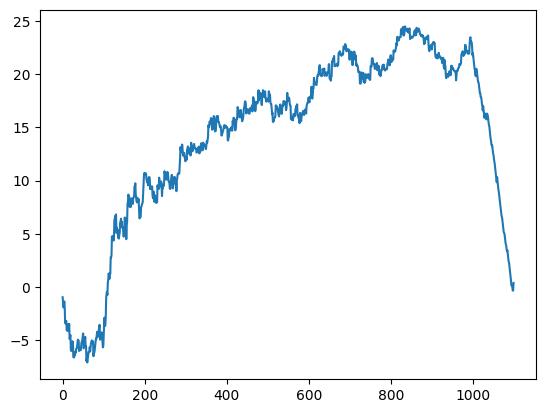

In [23]:
plt.plot(np.convolve(total_reward, np.ones(100)/100))

In [46]:
state = env.reset()
frames=[]
frame=env.render()
frames.append(frame)
episode_rewards=[]
while True: # gam haye yek episode
        action=agent.select_action(state)
        next_state,reward,done= env.step(action)
        episode_rewards.append(reward)
        agent.update(state, next_state, reward, action)
        state=next_state
        frame=env.render()
        frames.append(frame)
        if done:
            break

In [47]:
import imageio
imageio.mimsave('render.mp4' , frames, fps=2)
print(len(frames))

6


In [48]:
from IPython.display import Video, display
display(
    Video(
        'render.mp4',
        embed=True
    )
)